In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print("Libraries imported successfully!")

Libraries imported successfully!


In [46]:
from google.colab import files

uploaded = files.upload()

Saving EduPro Online Platform.xlsx - Courses.csv to EduPro Online Platform.xlsx - Courses (1).csv
Saving EduPro Online Platform.xlsx - Teachers.csv to EduPro Online Platform.xlsx - Teachers (1).csv
Saving EduPro Online Platform.xlsx - Transactions.csv to EduPro Online Platform.xlsx - Transactions (1).csv
Saving EduPro Online Platform.xlsx - Users (2).csv to EduPro Online Platform.xlsx - Users (2) (3).csv


In [47]:
users = pd.read_csv("/content/EduPro Online Platform.xlsx - Users (2) (1).csv")
courses = pd.read_csv("/content/EduPro Online Platform.xlsx - Courses.csv")
teachers = pd.read_csv("/content/EduPro Online Platform.xlsx - Teachers.csv")
transactions = pd.read_csv("/content/EduPro Online Platform.xlsx - Transactions.csv")

print("All 4 datasets loaded successfully!")

print("Users:", users.shape)
print("Courses:", courses.shape)
print("Teachers:", teachers.shape)
print("Transactions:", transactions.shape)

All 4 datasets loaded successfully!
Users: (3000, 5)
Courses: (60, 8)
Teachers: (60, 7)
Transactions: (10000, 7)


In [48]:
print("USERS DATA")
display(users.head())

print("COURSES DATA")
display(courses.head())

print("TEACHERS DATA")
display(teachers.head())

print("TRANSACTIONS DATA")
display(transactions.head())

USERS DATA


,UserID,UserName,Age,Gender,Email
0,U00001,wilsonjordan,15,Male,patricia27@hotmail.com
1,U00002,angela22,29,Female,hallrandy@hotmail.com
2,U00003,morrisonamanda,33,Female,ganderson@yahoo.com
3,U00004,fthornton,23,Female,christensencatherine@outlook.com
4,U00005,fostergeoffrey,21,Male,karenfuentes@yahoo.com


COURSES DATA


,CourseID,CourseName,CourseCategory,CourseType,CourseLevel,CoursePrice,CourseDuration,CourseRating
0,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.00,4.74
1,CR00002,Java Programming,Programming,Free,Intermediate,0.00,37.70,2.43
2,CR00003,C++ for Beginners,Programming,Free,Beginner,0.00,19.53,3.85
3,CR00004,Advanced Python,Programming,Free,Beginner,0.00,45.13,2.88
4,CR00005,Full Stack Development,Programming,Free,Beginner,0.00,28.68,1.28


TEACHERS DATA


,TeacherID,TeacherName,Age,Gender,Expertise,YearsOfExperience,TeacherRating
0,TC00001,Leonard Montgomery,44,Female,Cybersecurity,6,3.24
1,TC00002,Jill Day,32,Female,Digital Marketing,9,4.14
2,TC00003,Amber Torres,32,Male,Design,4,1.56
3,TC00004,Kristi Scott,34,Female,Machine Learning,9,4.39
4,TC00005,David Williams,34,Male,Finance,2,3.11


TRANSACTIONS DATA


,TransactionID,UserID,CourseID,TransactionDate,Amount,PaymentMethod,TeacherID
0,TT00001,U00003,CR00016,25/10/2025,0.0,PayPal,TC00040
1,TT00002,U00003,CR00037,13/1/2025,0.0,PayPal,TC00040
2,TT00003,U00003,CR00019,28/3/2025,0.0,Bank Transfer,TC00040
3,TT00004,U00004,CR00048,2/6/2025,0.0,Bank Transfer,TC00040
4,TT00005,U00004,CR00060,10/8/2025,0.0,PayPal,TC00042


In [49]:
print("USERS COLUMNS:")
print(users.columns.tolist())

print("\nCOURSES COLUMNS:")
print(courses.columns.tolist())

print("\nTEACHERS COLUMNS:")
print(teachers.columns.tolist())

print("\nTRANSACTIONS COLUMNS:")
print(transactions.columns.tolist())

USERS COLUMNS:
['UserID', 'UserName', 'Age', 'Gender', 'Email']

COURSES COLUMNS:
['CourseID', 'CourseName', 'CourseCategory', 'CourseType', 'CourseLevel', 'CoursePrice', 'CourseDuration', 'CourseRating']

TEACHERS COLUMNS:
['TeacherID', 'TeacherName', 'Age', 'Gender', 'Expertise', 'YearsOfExperience', 'TeacherRating']

TRANSACTIONS COLUMNS:
['TransactionID', 'UserID', 'CourseID', 'TransactionDate', 'Amount', 'PaymentMethod', 'TeacherID']


In [50]:
print("USERS INFO")
users.info()

print("\nCOURSES INFO")
courses.info()

print("\nTEACHERS INFO")
teachers.info()

print("\nTRANSACTIONS INFO")
transactions.info()

USERS INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   UserID    3000 non-null   object
 1   UserName  3000 non-null   object
 2   Age       3000 non-null   int64 
 3   Gender    3000 non-null   object
 4   Email     3000 non-null   object
dtypes: int64(1), object(4)
memory usage: 117.3+ KB

COURSES INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   CourseID        60 non-null     object 
 1   CourseName      60 non-null     object 
 2   CourseCategory  60 non-null     object 
 3   CourseType      60 non-null     object 
 4   CourseLevel     60 non-null     object 
 5   CoursePrice     60 non-null     float64
 6   CourseDuration  60 non-null     float64
 7   CourseRating    60 non-null     float64

In [51]:
print("USERS MISSING VALUES")
print(users.isnull().sum())

print("\nCOURSES MISSING VALUES")
print(courses.isnull().sum())

print("\nTEACHERS MISSING VALUES")
print(teachers.isnull().sum())

print("\nTRANSACTIONS MISSING VALUES")
print(transactions.isnull().sum())

USERS MISSING VALUES
UserID      0
UserName    0
Age         0
Gender      0
Email       0
dtype: int64

COURSES MISSING VALUES
CourseID          0
CourseName        0
CourseCategory    0
CourseType        0
CourseLevel       0
CoursePrice       0
CourseDuration    0
CourseRating      0
dtype: int64

TEACHERS MISSING VALUES
TeacherID            0
TeacherName          0
Age                  0
Gender               0
Expertise            0
YearsOfExperience    0
TeacherRating        0
dtype: int64

TRANSACTIONS MISSING VALUES
TransactionID      0
UserID             0
CourseID           0
TransactionDate    0
Amount             0
PaymentMethod      0
TeacherID          0
dtype: int64


In [52]:
print("Users Duplicates:", users.duplicated().sum())
print("Courses Duplicates:", courses.duplicated().sum())
print("Teachers Duplicates:", teachers.duplicated().sum())
print("Transactions Duplicates:", transactions.duplicated().sum())

Users Duplicates: 0
Courses Duplicates: 0
Teachers Duplicates: 0
Transactions Duplicates: 0


**DATA ANALYSIS**

In [53]:
print("TOTAL USERS:", users['UserID'].nunique())

print("\nGENDER DISTRIBUTION:")
print(users['Gender'].value_counts())

print("\nAGE STATISTICS:")
print(users['Age'].describe())


TOTAL USERS: 3000

GENDER DISTRIBUTION:
Gender
Female    1520
Male      1480
Name: count, dtype: int64

AGE STATISTICS:
count    3000.000000
mean       24.974333
std         6.046475
min        15.000000
25%        20.000000
50%        25.000000
75%        30.000000
max        35.000000
Name: Age, dtype: float64


In [54]:
print("TOTAL COURSES:", courses['CourseID'].nunique())

print("\nCOURSE CATEGORY DISTRIBUTION:")
print(courses['CourseCategory'].value_counts())

print("\nCOURSE TYPE DISTRIBUTION:")
print(courses['CourseType'].value_counts())

print("\nCOURSE LEVEL DISTRIBUTION:")
print(courses['CourseLevel'].value_counts())

print("\nCOURSE PRICE STATISTICS:")
print(courses['CoursePrice'].describe())

print("\nCOURSE RATING STATISTICS:")
print(courses['CourseRating'].describe())


TOTAL COURSES: 60

COURSE CATEGORY DISTRIBUTION:
CourseCategory
Programming                5
Design                     5
Business                   5
Marketing                  5
Data Science               5
Machine Learning           5
Cybersecurity              5
Project Management         5
Finance                    5
Artificial Intelligence    5
Web Development            5
Digital Marketing          5
Name: count, dtype: int64

COURSE TYPE DISTRIBUTION:
CourseType
Free    38
Paid    22
Name: count, dtype: int64

COURSE LEVEL DISTRIBUTION:
CourseLevel
Beginner        21
Advanced        21
Intermediate    18
Name: count, dtype: int64

COURSE PRICE STATISTICS:
count     60.000000
mean      92.986333
std      153.601506
min        0.000000
25%        0.000000
50%        0.000000
75%      133.615000
max      490.900000
Name: CoursePrice, dtype: float64

COURSE RATING STATISTICS:
count    60.000000
mean      3.097833
std       1.171232
min       1.130000
25%       2.107500
50%       3

In [55]:
print("TOTAL TEACHERS:", teachers['TeacherID'].nunique())

print("\nTEACHER GENDER DISTRIBUTION:")
print(teachers['Gender'].value_counts())

print("\nTEACHER EXPERTISE:")
print(teachers['Expertise'].value_counts())

print("\nYEARS OF EXPERIENCE:")
print(teachers['YearsOfExperience'].describe())

print("\nTEACHER RATINGS:")
print(teachers['TeacherRating'].describe())

TOTAL TEACHERS: 60

TEACHER GENDER DISTRIBUTION:
Gender
Male      33
Female    27
Name: count, dtype: int64

TEACHER EXPERTISE:
Expertise
Digital Marketing          11
Cybersecurity               9
Artificial Intelligence     6
Finance                     6
Web Development             5
Machine Learning            5
Data Science                5
Project Management          5
Design                      4
Business                    2
Marketing                   1
Programming                 1
Name: count, dtype: int64

YEARS OF EXPERIENCE:
count    60.000000
mean      6.283333
std       4.715972
min       1.000000
25%       3.000000
50%       6.000000
75%       8.000000
max      24.000000
Name: YearsOfExperience, dtype: float64

TEACHER RATINGS:
count    60.000000
mean      3.125000
std       0.949797
min       1.050000
25%       2.487500
50%       3.275000
75%       3.827500
max       4.970000
Name: TeacherRating, dtype: float64


In [56]:
print("TOTAL TRANSACTIONS:", transactions['TransactionID'].nunique())

print("\nTOTAL REVENUE:")
print(transactions['Amount'].sum())

print("\nAVERAGE TRANSACTION AMOUNT:")
print(transactions['Amount'].mean())

print("\nPAYMENT METHOD DISTRIBUTION:")
print(transactions['PaymentMethod'].value_counts())

print("\nTRANSACTION DATE RANGE:")
print(transactions['TransactionDate'].min())
print(transactions['TransactionDate'].max())

TOTAL TRANSACTIONS: 10000

TOTAL REVENUE:
911323.47

AVERAGE TRANSACTION AMOUNT:
91.132347

PAYMENT METHOD DISTRIBUTION:
PaymentMethod
PayPal           3389
Credit Card      3333
Bank Transfer    3278
Name: count, dtype: int64

TRANSACTION DATE RANGE:
1/1/2025
9/9/2025


**DATA PREPARATION**

In [57]:
transactions['TransactionDate'] = pd.to_datetime(
    transactions['TransactionDate'],
    errors='coerce'
)

print(transactions['TransactionDate'].dtype)
print(transactions['TransactionDate'].head())

datetime64[ns]
0   2025-10-25
1   2025-01-13
2   2025-03-28
3   2025-06-02
4   2025-08-10
Name: TransactionDate, dtype: datetime64[ns]


/tmp/ipykernel_1991/3505338749.py:1: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  transactions['TransactionDate'] = pd.to_datetime(


In [58]:
print("Missing Dates:", transactions['TransactionDate'].isna().sum())

print("\nInvalid Transaction Dates:")
print(transactions[transactions['TransactionDate'].isna()])

Missing Dates: 0

Invalid Transaction Dates:
Empty DataFrame
Columns: [TransactionID, UserID, CourseID, TransactionDate, Amount, PaymentMethod, TeacherID]
Index: []


In [59]:
course_demand = transactions.groupby('CourseID').size().reset_index(name='Enrollment_Count')

print(course_demand.head(10))

  CourseID  Enrollment_Count
0  CR00001               164
1  CR00002               149
2  CR00003               173
3  CR00004               154
4  CR00005               166
5  CR00006               156
6  CR00007               178
7  CR00008               158
8  CR00009               155
9  CR00010               180


In [60]:
course_analysis = courses.merge(
    course_demand,
    on='CourseID',
    how='left'
)

course_analysis['Enrollment_Count'] = course_analysis['Enrollment_Count'].fillna(0)

print(course_analysis.head())

  CourseID              CourseName CourseCategory CourseType   CourseLevel  \
0  CR00001           Python Basics    Programming       Paid      Beginner   
1  CR00002        Java Programming    Programming       Free  Intermediate   
2  CR00003       C++ for Beginners    Programming       Free      Beginner   
3  CR00004         Advanced Python    Programming       Free      Beginner   
4  CR00005  Full Stack Development    Programming       Free      Beginner   

   CoursePrice  CourseDuration  CourseRating  Enrollment_Count  
0       472.28           11.00          4.74               164  
1         0.00           37.70          2.43               149  
2         0.00           19.53          3.85               173  
3         0.00           45.13          2.88               154  
4         0.00           28.68          1.28               166  


**REVENUE ANALYSIS**

In [61]:
course_revenue = transactions.groupby('CourseID')['Amount'].sum().reset_index()

course_revenue.columns = ['CourseID', 'Course_Revenue']

print(course_revenue.head(10))

  CourseID  Course_Revenue
0  CR00001        77453.92
1  CR00002            0.00
2  CR00003            0.00
3  CR00004            0.00
4  CR00005            0.00
5  CR00006        43113.72
6  CR00007            0.00
7  CR00008            0.00
8  CR00009            0.00
9  CR00010            0.00


In [62]:
course_analysis = course_analysis.merge(
    course_revenue,
    on='CourseID',
    how='left'
)

course_analysis['Course_Revenue'] = course_analysis['Course_Revenue'].fillna(0)

print(course_analysis.head())

  CourseID              CourseName CourseCategory CourseType   CourseLevel  \
0  CR00001           Python Basics    Programming       Paid      Beginner   
1  CR00002        Java Programming    Programming       Free  Intermediate   
2  CR00003       C++ for Beginners    Programming       Free      Beginner   
3  CR00004         Advanced Python    Programming       Free      Beginner   
4  CR00005  Full Stack Development    Programming       Free      Beginner   

   CoursePrice  CourseDuration  CourseRating  Enrollment_Count  Course_Revenue  
0       472.28           11.00          4.74               164        77453.92  
1         0.00           37.70          2.43               149            0.00  
2         0.00           19.53          3.85               173            0.00  
3         0.00           45.13          2.88               154            0.00  
4         0.00           28.68          1.28               166            0.00  


In [63]:
top_revenue_courses = course_analysis.sort_values(
    by='Course_Revenue',
    ascending=False
)

print(top_revenue_courses[
    ['CourseName', 'CourseCategory', 'Course_Revenue']
].head(10))

                CourseName           CourseCategory  Course_Revenue
49         Computer Vision  Artificial Intelligence        85416.60
11       Business Strategy                 Business        84410.16
0            Python Basics              Programming        77453.92
48           Deep Learning  Artificial Intelligence        67728.13
33         Data Encryption            Cybersecurity        59139.00
38        Project Planning       Project Management        57900.57
24    Statistical Analysis             Data Science        57517.44
39  Leadership in Projects       Project Management        57070.26
37         Risk Management       Project Management        54132.38
10    Entrepreneurship 101                 Business        49229.02


In [64]:
top_demand_courses = course_analysis.sort_values(
    by='Enrollment_Count',
    ascending=False
)

print(top_demand_courses[
    ['CourseName', 'CourseCategory', 'Enrollment_Count']
].head(10))

                       CourseName           CourseCategory  Enrollment_Count
20      Data Analysis with Python             Data Science               196
57          Social Media Strategy        Digital Marketing               194
24           Statistical Analysis             Data Science               192
47                      AI Ethics  Artificial Intelligence               186
22  Machine Learning Fundamentals             Data Science               185
41          Investment Strategies                  Finance               183
42              Corporate Finance                  Finance               182
9                     3D Modeling                   Design               180
34      Cyber Threat Intelligence            Cybersecurity               179
6                    UI/UX Design                   Design               178


**DATA VISUALIZATION 📊**

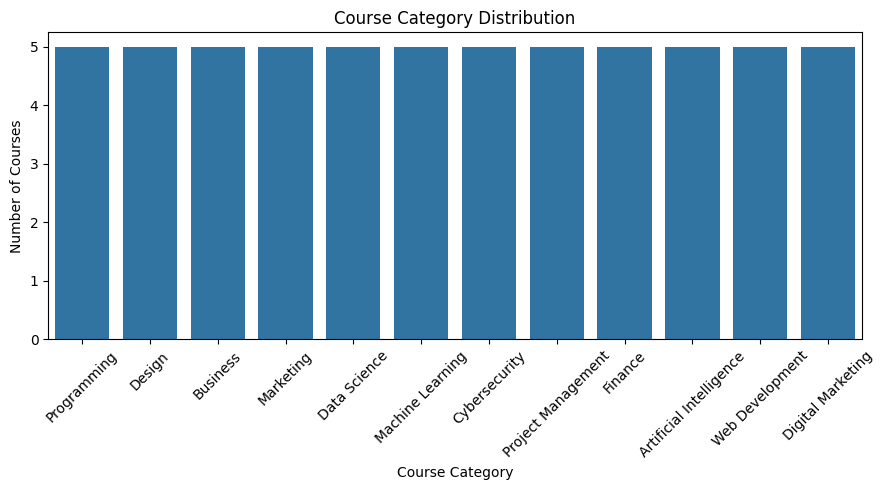

In [65]:
plt.figure(figsize=(9, 5))

sns.countplot(data=courses, x='CourseCategory')

plt.title('Course Category Distribution')
plt.xlabel('Course Category')
plt.ylabel('Number of Courses')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

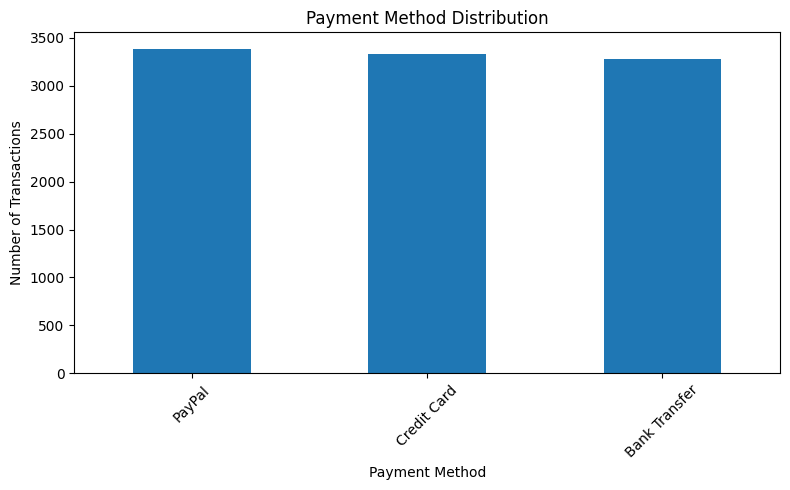

In [66]:
plt.figure(figsize=(8, 5))

transactions['PaymentMethod'].value_counts().plot(kind='bar')

plt.title('Payment Method Distribution')
plt.xlabel('Payment Method')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

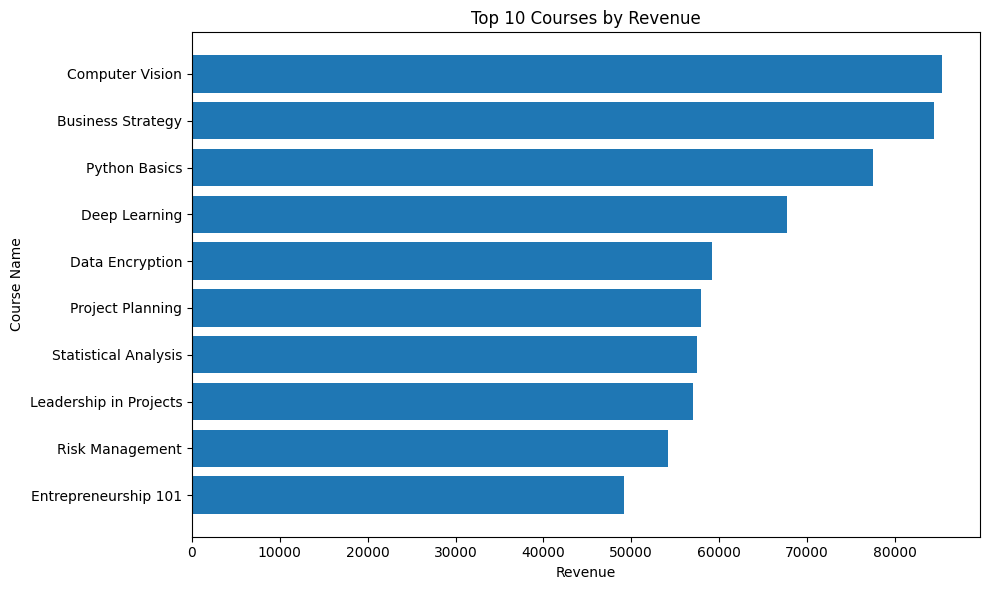

In [67]:
top10 = course_analysis.nlargest(10, 'Course_Revenue')

plt.figure(figsize=(10, 6))

plt.barh(top10['CourseName'], top10['Course_Revenue'])

plt.title('Top 10 Courses by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Course Name')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

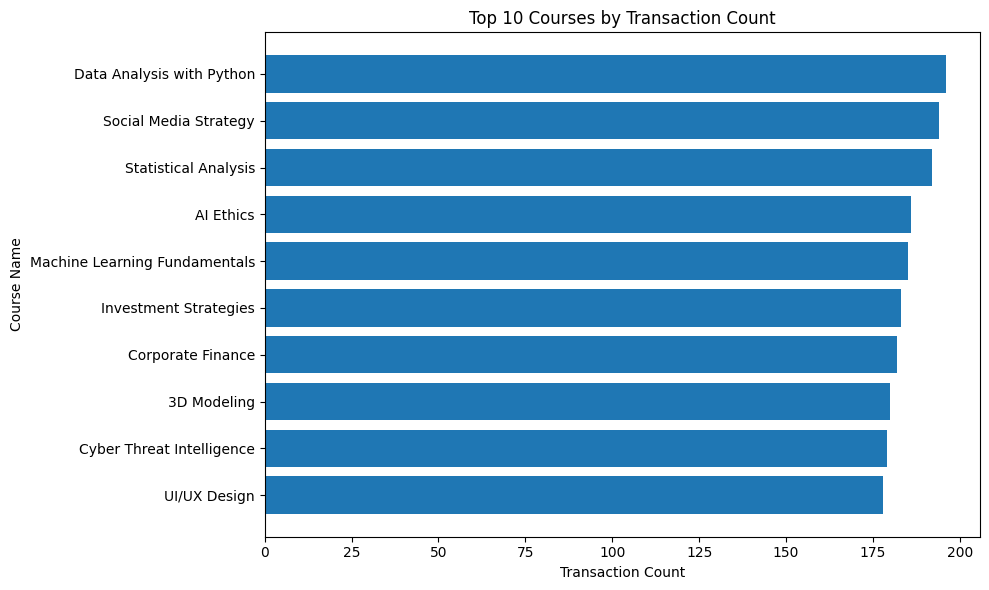

In [68]:
top10_demand = course_analysis.nlargest(10, 'Enrollment_Count')

plt.figure(figsize=(10, 6))

plt.barh(
    top10_demand['CourseName'],
    top10_demand['Enrollment_Count']
)

plt.title('Top 10 Courses by Transaction Count')
plt.xlabel('Transaction Count')
plt.ylabel('Course Name')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

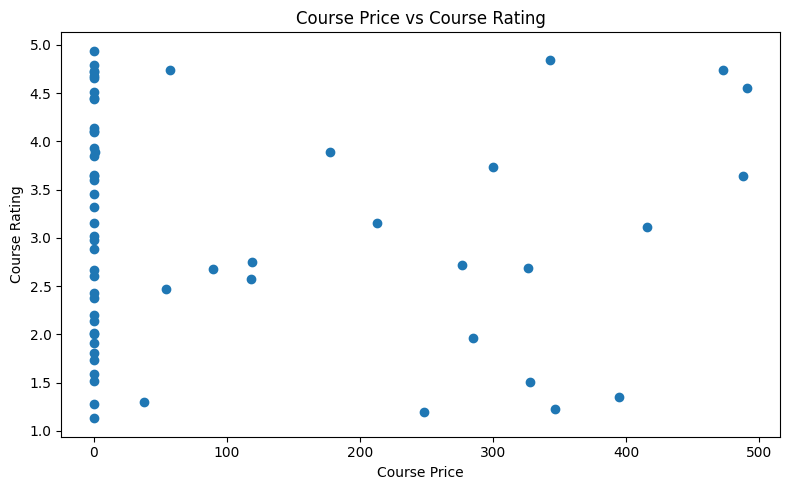

In [69]:
plt.figure(figsize=(8, 5))

plt.scatter(
    courses['CoursePrice'],
    courses['CourseRating']
)

plt.title('Course Price vs Course Rating')
plt.xlabel('Course Price')
plt.ylabel('Course Rating')
plt.tight_layout()
plt.show()

**DATA FOR REVENUE FORECASTING**

In [70]:
daily_revenue = (
    transactions.dropna(subset=['TransactionDate'])
    .groupby(transactions.dropna(subset=['TransactionDate'])['TransactionDate'].dt.date)['Amount']
    .sum()
    .reset_index()
)

daily_revenue.columns = ['Date', 'Revenue']

print(daily_revenue.head())

         Date  Revenue
0  2025-01-01  1381.73
1  2025-01-02  3237.14
2  2025-01-03  2177.75
3  2025-01-04  2177.89
4  2025-01-05  3981.14


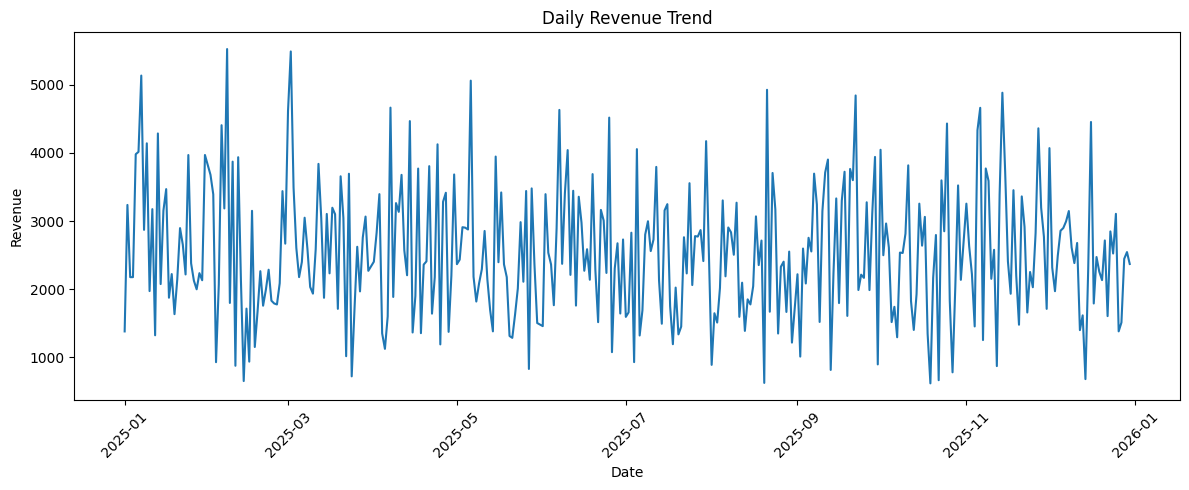

In [71]:
plt.figure(figsize=(12, 5))

plt.plot(daily_revenue['Date'], daily_revenue['Revenue'])

plt.title('Daily Revenue Trend')
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**PREDICTIVE MODELING**

In [72]:
model_data = course_analysis.copy()

features = [
    'CoursePrice',
    'CourseDuration',
    'CourseRating'
]

X = model_data[features].copy()
y = model_data['Enrollment_Count'].copy()

X = X.fillna(X.median())

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   CoursePrice  CourseDuration  CourseRating
0       472.28           11.00          4.74
1         0.00           37.70          2.43
2         0.00           19.53          3.85
3         0.00           45.13          2.88
4         0.00           28.68          1.28

Target:
0    164
1    149
2    173
3    154
4    166
Name: Enrollment_Count, dtype: int64


In [73]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 48
Testing rows: 12


In [74]:
demand_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

demand_model.fit(X_train, y_train)

print("Demand Model Training Completed!")

Demand Model Training Completed!


In [75]:
y_pred = demand_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))

print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)

print("R2 Score:", r2_score(y_test, y_pred))

MAE: 11.28333333333333
RMSE: 13.873732374527048
R2 Score: -0.056295152439024054


**COURSE REVENUE PREDICTION**

In [76]:
revenue_data = course_analysis.copy()

X_rev = revenue_data[
    ['CoursePrice', 'CourseDuration', 'CourseRating']
].copy()

y_rev = revenue_data['Course_Revenue'].copy()

X_rev = X_rev.fillna(X_rev.median())

print(X_rev.head())
print(y_rev.head())

   CoursePrice  CourseDuration  CourseRating
0       472.28           11.00          4.74
1         0.00           37.70          2.43
2         0.00           19.53          3.85
3         0.00           45.13          2.88
4         0.00           28.68          1.28
0    77453.92
1        0.00
2        0.00
3        0.00
4        0.00
Name: Course_Revenue, dtype: float64


In [77]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_rev,
    y_rev,
    test_size=0.2,
    random_state=42
)

In [78]:
revenue_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

revenue_model.fit(Xr_train, yr_train)

print("Revenue Model Training Completed!")

Revenue Model Training Completed!


In [79]:
yr_pred = revenue_model.predict(Xr_test)

print("Revenue MAE:", mean_absolute_error(yr_test, yr_pred))

print("Revenue RMSE:", mean_squared_error(yr_test, yr_pred) ** 0.5)

print("Revenue R2 Score:", r2_score(yr_test, yr_pred))

Revenue MAE: 2786.222566666658
Revenue RMSE: 3967.6899980355556
Revenue R2 Score: 0.9797181851931036


**CATEGORY REVENUE ANALYSIS**

In [80]:
category_revenue = transactions.merge(
    courses[['CourseID', 'CourseCategory']],
    on='CourseID',
    how='left'
)

category_summary = category_revenue.groupby(
    'CourseCategory'
)['Amount'].sum().reset_index()

category_summary.columns = ['CourseCategory', 'Category_Revenue']

print(category_summary.sort_values(
    by='Category_Revenue',
    ascending=False
))

             CourseCategory  Category_Revenue
0   Artificial Intelligence         202750.67
1                  Business         181527.58
10       Project Management         169103.21
9               Programming          77453.92
3              Data Science          77052.32
2             Cybersecurity          59139.00
5         Digital Marketing          56261.32
4                    Design          43113.72
6                   Finance          28106.20
11          Web Development          16682.15
7          Machine Learning            133.38
8                 Marketing              0.00


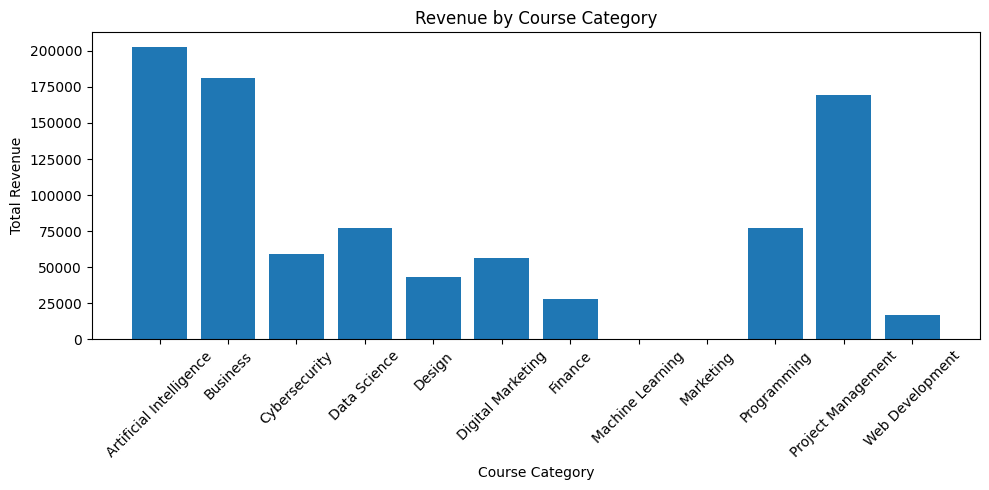

In [81]:
plt.figure(figsize=(10, 5))

plt.bar(
    category_summary['CourseCategory'],
    category_summary['Category_Revenue']
)

plt.title('Revenue by Course Category')
plt.xlabel('Course Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [82]:
users.to_csv('cleaned_users.csv', index=False)
courses.to_csv('cleaned_courses.csv', index=False)
teachers.to_csv('cleaned_teachers.csv', index=False)
transactions.to_csv('cleaned_transactions.csv', index=False)

course_analysis.to_csv('course_analysis.csv', index=False)
category_summary.to_csv('category_revenue.csv', index=False)

print("All files saved successfully!")

All files saved successfully!


In [83]:
from google.colab import files

files.download('course_analysis.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>